<a href="https://colab.research.google.com/github/Tushar-3512/Data-Science-Practical-/blob/main/Practical10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("yasserh/wine-quality-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'wine-quality-dataset' dataset.
Path to dataset files: /kaggle/input/wine-quality-dataset


In [ ]:
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

csv_file = glob.glob(path + "/*.csv")[0]
df = pd.read_csv(csv_file)

if "Id" in df.columns:
    df = df.drop(columns=["Id"])

print("Dataset loaded from:", csv_file)
print("Shape (rows, columns):", df.shape)
print(df.head())

Dataset loaded from: /kaggle/input/wine-quality-dataset/WineQT.csv
Shape (rows, columns): (1143, 12)
   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.9980  3.16       0.58   
4                 11.0                  34.0   0.9978  3.51 

1. Display the Basic Statistics using describe ()

In [ ]:
print(df.describe().T)
print("comparing mean with the 50% value (median) tells us about skewness, e.g. 'residual sugar' and 'chlorides' are right-skewed")
print("the features are on very different scales (total sulfur dioxide is in the 100s,chlorides is below,which is why scaling is needed later")

                       count       mean        std      min       25%  \
fixed acidity         1143.0   8.311111   1.747595  4.60000   7.10000   
volatile acidity      1143.0   0.531339   0.179633  0.12000   0.39250   
citric acid           1143.0   0.268364   0.196686  0.00000   0.09000   
residual sugar        1143.0   2.532152   1.355917  0.90000   1.90000   
chlorides             1143.0   0.086933   0.047267  0.01200   0.07000   
free sulfur dioxide   1143.0  15.615486  10.250486  1.00000   7.00000   
total sulfur dioxide  1143.0  45.914698  32.782130  6.00000  21.00000   
density               1143.0   0.996730   0.001925  0.99007   0.99557   
pH                    1143.0   3.311015   0.156664  2.74000   3.20500   
sulphates             1143.0   0.657708   0.170399  0.33000   0.55000   
alcohol               1143.0  10.442111   1.082196  8.40000   9.50000   
quality               1143.0   5.657043   0.805824  3.00000   5.00000   

                           50%        75%        m

2. Boxplot by output labels/classes

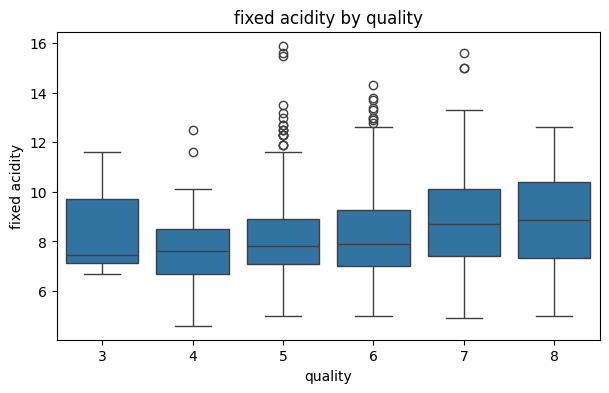

Explanation for fixed acidity :
1. Fixed acidity shows the non-volatile acids in the wine for each quality score.
2. The median stays almost the same across qualities, with many high outliers.
3. The boxes overlap heavily, so it is a weak separator between the classes.



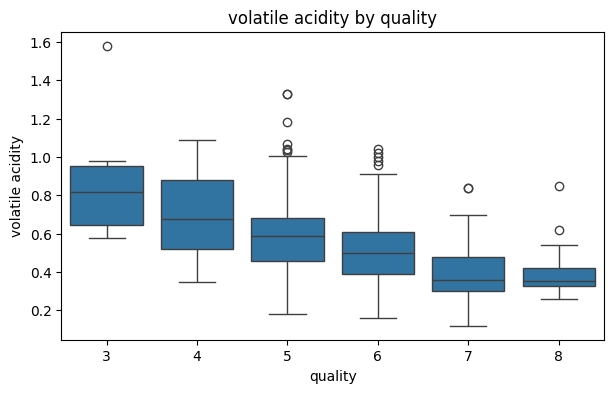

Explanation for volatile acidity :
1. Volatile acidity measures acetic acid, which gives a vinegar smell, for each quality score.
2. The median goes down clearly as quality goes up, so better wines have less of it.
3. This makes it a strong separator between low and high quality wines.



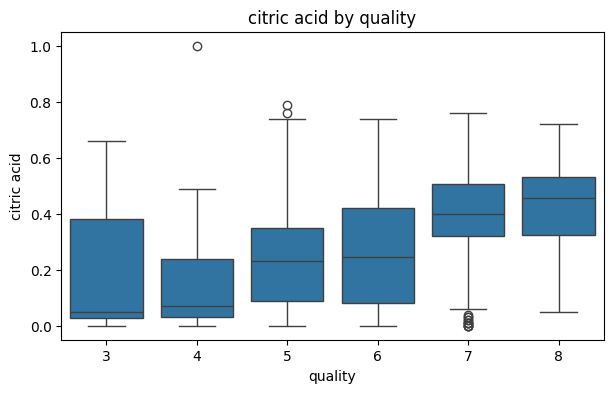

Explanation for citric acid :
1. Citric acid adds freshness to the wine and is compared across quality scores here.
2. The median tends to increase as quality increases, so better wines have more citric acid.
3. The boxes still overlap a little, so it is a moderate separator.



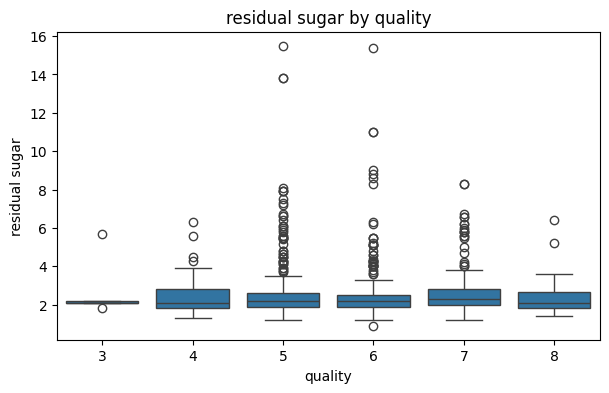

Explanation for residual sugar :
1. Residual sugar is the sugar left in the wine after fermentation.
2. The medians are nearly equal for every quality, and there are many high outliers.
3. Since the boxes look almost identical, it is a weak separator.



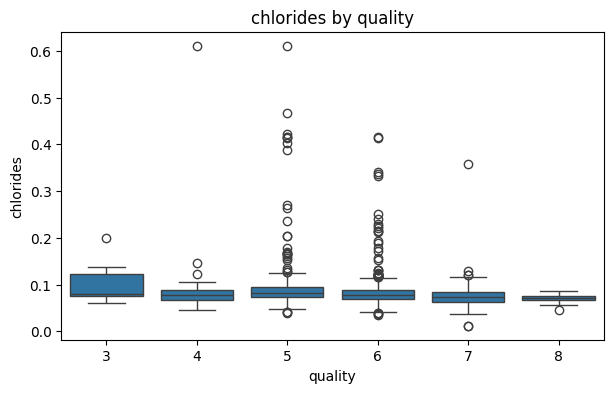

Explanation for chlorides :
1. Chlorides measure the salt content of the wine for each quality score.
2. Most values are very small, so the boxes are squeezed at the bottom with many outliers above them.
3. The difference between qualities is small, so it is a weak separator.



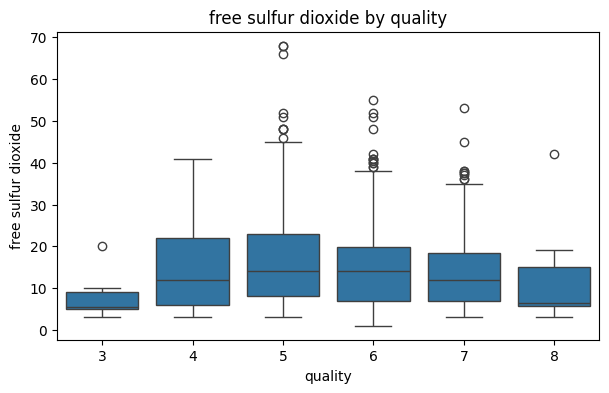

Explanation for free sulfur dioxide :
1. Free sulfur dioxide protects the wine from spoiling and is compared across quality scores.
2. The median is highest for the middle qualities (5 and 6) and lower for the extreme ones.
3. There is no steady up or down trend, so it is not a reliable separator on its own.



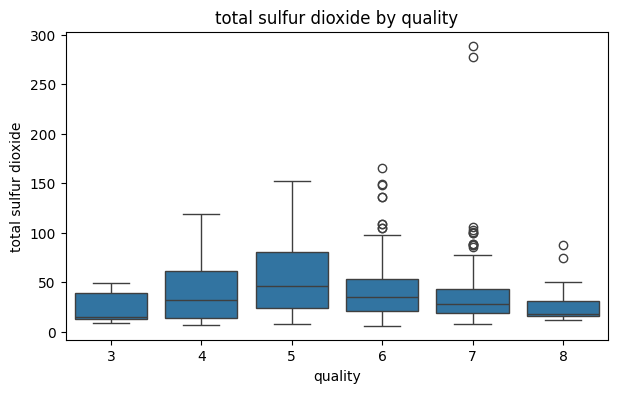

Explanation for total sulfur dioxide :
1. Total sulfur dioxide is the free plus bound sulfur dioxide in the wine.
2. The median is higher for average wines (5 and 6) and lower for high quality wines (7 and 8).
3. The spread is wide with many outliers, so it is a moderate separator.



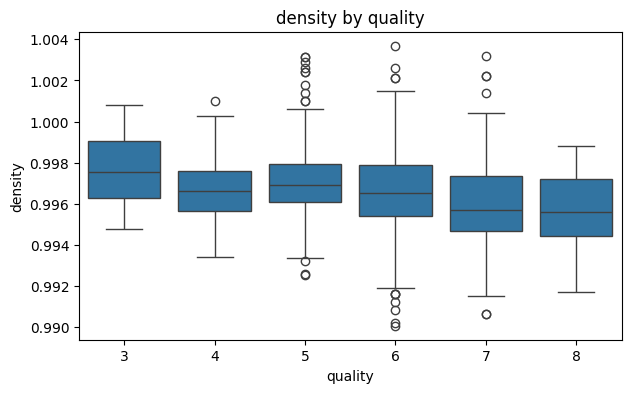

Explanation for density :
1. Density of the wine is plotted for each quality score.
2. All values are very close to 1, and better wines have a slightly lower median density.
3. The boxes overlap a lot, so it is only a weak to moderate separator.



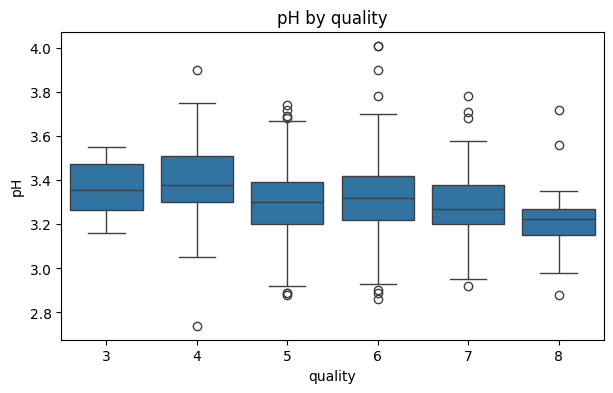

Explanation for pH :
1. pH tells us how acidic the wine is for each quality score.
2. The medians stay in a narrow range for all qualities, with outliers on both sides.
3. The boxes overlap almost completely, so it is a weak separator.



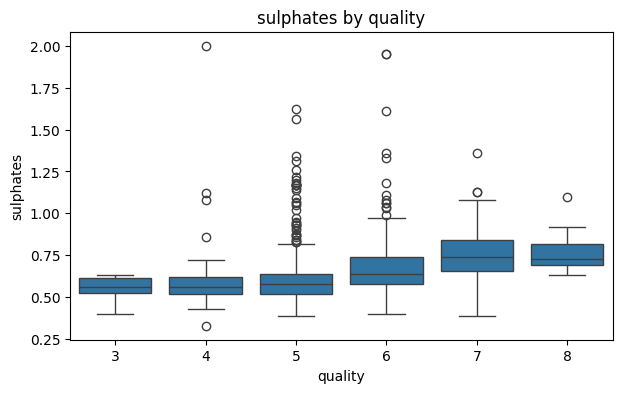

Explanation for sulphates :
1. Sulphates are an additive that helps preserve the wine, shown for each quality score.
2. The median rises as quality rises, with some high outliers in the middle qualities.
3. The upward trend makes it a good separator between low and high quality wines.



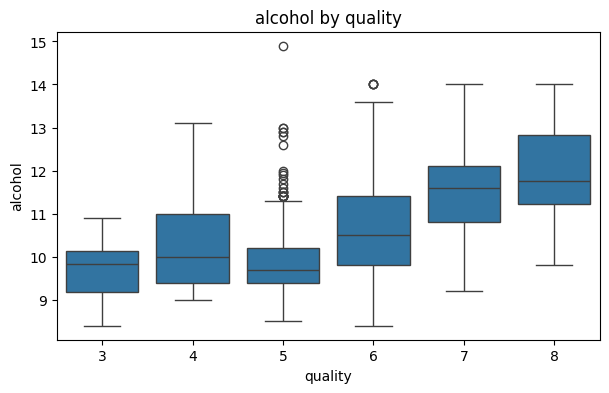

Explanation for alcohol :
1. Alcohol is the percentage of alcohol in the wine for each quality score.
2. The median increases steadily as quality increases, which is the clearest trend of all features.
3. This makes it the strongest separator and the most useful single feature for predicting quality.



In [ ]:
#Making a list of all input columns everything except quality
features = []
for col in df.columns:
    if col != "quality":
        features.append(col)

explanations = {
    "fixed acidity": [
        "Fixed acidity shows the non-volatile acids in the wine for each quality score.",
        "The median stays almost the same across qualities, with many high outliers.",
        "The boxes overlap heavily, so it is a weak separator between the classes.",
    ],
    "volatile acidity": [
        "Volatile acidity measures acetic acid, which gives a vinegar smell, for each quality score.",
        "The median goes down clearly as quality goes up, so better wines have less of it.",
        "This makes it a strong separator between low and high quality wines.",
    ],
    "citric acid": [
        "Citric acid adds freshness to the wine and is compared across quality scores here.",
        "The median tends to increase as quality increases, so better wines have more citric acid.",
        "The boxes still overlap a little, so it is a moderate separator.",
    ],
    "residual sugar": [
        "Residual sugar is the sugar left in the wine after fermentation.",
        "The medians are nearly equal for every quality, and there are many high outliers.",
        "Since the boxes look almost identical, it is a weak separator.",
    ],
    "chlorides": [
        "Chlorides measure the salt content of the wine for each quality score.",
        "Most values are very small, so the boxes are squeezed at the bottom with many outliers above them.",
        "The difference between qualities is small, so it is a weak separator.",
    ],
    "free sulfur dioxide": [
        "Free sulfur dioxide protects the wine from spoiling and is compared across quality scores.",
        "The median is highest for the middle qualities (5 and 6) and lower for the extreme ones.",
        "There is no steady up or down trend, so it is not a reliable separator on its own.",
    ],
    "total sulfur dioxide": [
        "Total sulfur dioxide is the free plus bound sulfur dioxide in the wine.",
        "The median is higher for average wines (5 and 6) and lower for high quality wines (7 and 8).",
        "The spread is wide with many outliers, so it is a moderate separator.",
    ],
    "density": [
        "Density of the wine is plotted for each quality score.",
        "All values are very close to 1, and better wines have a slightly lower median density.",
        "The boxes overlap a lot, so it is only a weak to moderate separator.",
    ],
    "pH": [
        "pH tells us how acidic the wine is for each quality score.",
        "The medians stay in a narrow range for all qualities, with outliers on both sides.",
        "The boxes overlap almost completely, so it is a weak separator.",
    ],
    "sulphates": [
        "Sulphates are an additive that helps preserve the wine, shown for each quality score.",
        "The median rises as quality rises, with some high outliers in the middle qualities.",
        "The upward trend makes it a good separator between low and high quality wines.",
    ],
    "alcohol": [
        "Alcohol is the percentage of alcohol in the wine for each quality score.",
        "The median increases steadily as quality increases, which is the clearest trend of all features.",
        "This makes it the strongest separator and the most useful single feature for predicting quality.",
    ],
}

#Drawing one boxplot per feature
for col in features:
    plt.figure(figsize=(7, 4))
    sns.boxplot(x="quality", y=col, data=df)
    plt.title(col + " by quality")
    plt.show()

    print("Explanation for", col, ":")
    if col in explanations:
        line_number = 1
        for line in explanations[col]:
            print(str(line_number) + ".", line)
            line_number = line_number + 1
    print()

3. Scatterplot using two variable

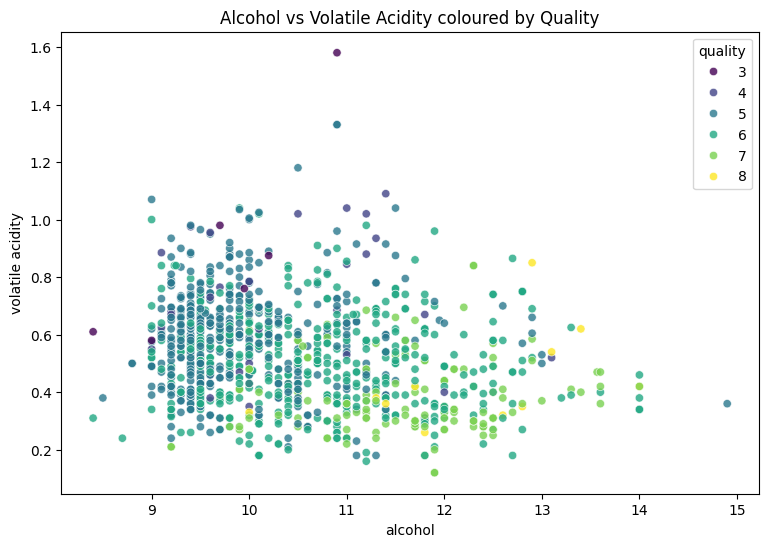

1. This scatterplot compares two variables, 'alcohol' (x-axis) and 'volatile acidity' (y-axis), and colours each wine by quality.
2. High quality wines tend to sit toward the bottom-right, meaning higher alcohol and lower volatile acidity.
3. Low quality wines cluster toward the top-left, meaning lower alcohol and higher volatile acidity.
4. The classes still overlap a lot, so two features alone cannot separate them cleanly, which motivates PCA in the last step.


In [ ]:
plt.figure(figsize=(9, 6))
sns.scatterplot(x="alcohol", y="volatile acidity", hue="quality",
                data=df, palette="viridis", alpha=0.8)
plt.title("Alcohol vs Volatile Acidity coloured by Quality")
plt.show()

print("1. This scatterplot compares two variables, 'alcohol' (x-axis) and 'volatile acidity' (y-axis), and colours each wine by quality.")
print("2. High quality wines tend to sit toward the bottom-right, meaning higher alcohol and lower volatile acidity.")
print("3. Low quality wines cluster toward the top-left, meaning lower alcohol and higher volatile acidity.")
print("4. The classes still overlap a lot, so two features alone cannot separate them cleanly, which motivates PCA in the last step.")

4. Plot Co-Variance Matrix

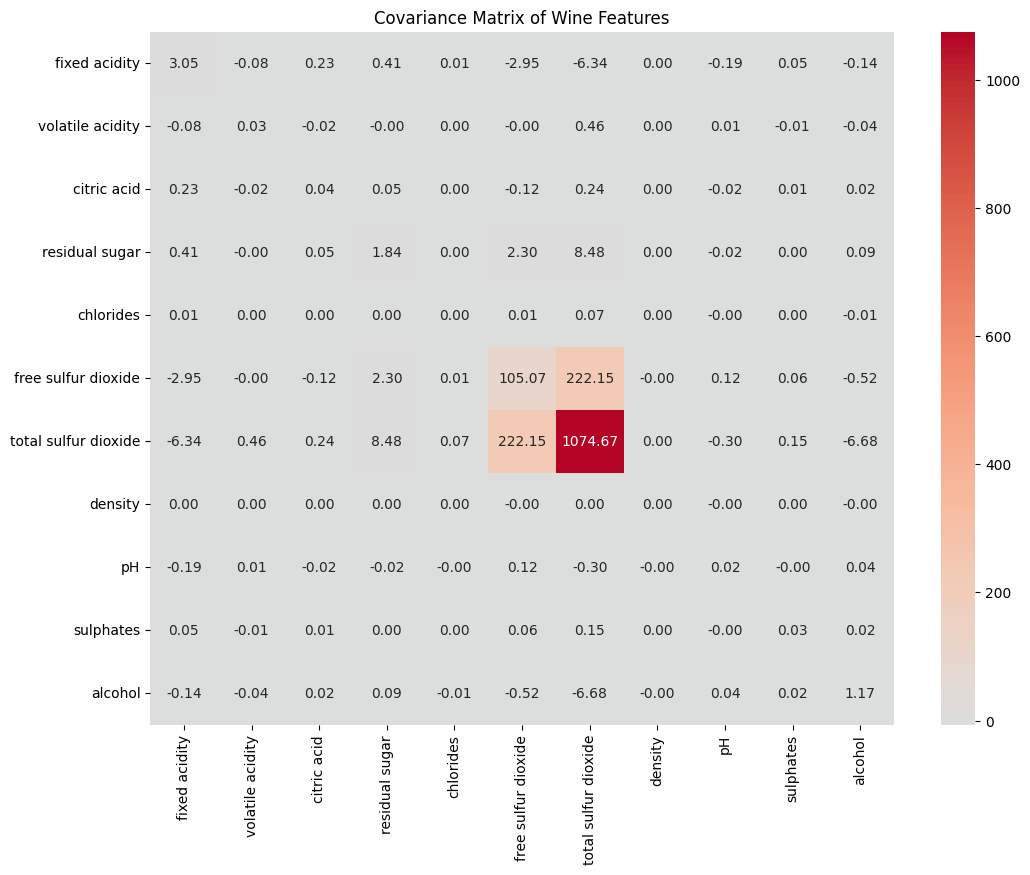

1. The covariance matrix shows how each pair of features varies together: positive means they rise together, negative means one rises as the other falls.
2. The diagonal holds the variance of each feature, and 'total sulfur dioxide' dominates because it has the largest scale.
3. Covariance depends on the units of the features, so large-scale features look more important than they really are.
4. This is exactly why we standardise the data in the next step, after which the covariance matrix becomes the correlation matrix.


In [ ]:
cov_matrix = df[features].cov()

plt.figure(figsize=(12, 9))
sns.heatmap(cov_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Covariance Matrix of Wine Features")
plt.show()

print("1. The covariance matrix shows how each pair of features varies together: positive means they rise together, negative means one rises as the other falls.")
print("2. The diagonal holds the variance of each feature, and 'total sulfur dioxide' dominates because it has the largest scale.")
print("3. Covariance depends on the units of the features, so large-scale features look more important than they really are.")
print("4. This is exactly why we standardise the data in the next step, after which the covariance matrix becomes the correlation matrix.")

5. Data Scaling

In [ ]:
from sklearn.preprocessing import StandardScaler

X = df[features]
y = df["quality"]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled_df = pd.DataFrame(X_scaled, columns=features)

print("Mean after scaling (should be ~0):")
print(X_scaled_df.mean().round(3))
print("\nStd after scaling (should be 1):")
print(X_scaled_df.std().round(3))

print("1. StandardScaler transforms every feature using z = (x - mean) / std, giving mean 0 and standard deviation 1.")
print("2. The printed means are about 0 and the standard deviations are about 1, which confirms the scaling worked.")
print("3. Now every feature contributes equally, so large-scale features like sulfur dioxide no longer dominate.")
print("4. Scaling is essential before PCA, because PCA picks directions of maximum variance and would otherwise just follow the biggest-scale feature.")

Mean after scaling (should be ~0):
fixed acidity          -0.0
volatile acidity        0.0
citric acid             0.0
residual sugar          0.0
chlorides               0.0
free sulfur dioxide    -0.0
total sulfur dioxide    0.0
density                 0.0
pH                     -0.0
sulphates               0.0
alcohol                -0.0
dtype: float64

Std after scaling (should be 1):
fixed acidity           1.0
volatile acidity        1.0
citric acid             1.0
residual sugar          1.0
chlorides               1.0
free sulfur dioxide     1.0
total sulfur dioxide    1.0
density                 1.0
pH                      1.0
sulphates               1.0
alcohol                 1.0
dtype: float64
1. StandardScaler transforms every feature using z = (x - mean) / std, giving mean 0 and standard deviation 1.
2. The printed means are about 0 and the standard deviations are about 1, which confirms the scaling worked.
3. Now every feature contributes equally, so large-scale features

6. Show better class separation using principal components

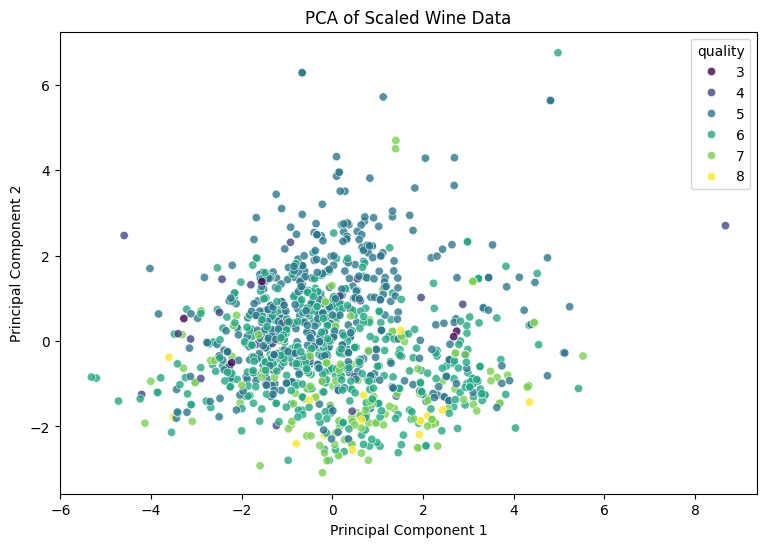

Variance explained by each component: [0.287 0.171]
Total variance captured by 2 components: 0.458
1. PCA (Principal Component Analysis) combines our 11 correlated wine features into new axes called principal components.
2. We used the scaled data (X_scaled) because PCA looks for directions of maximum variance, and unscaled features with big values would dominate.
3. Principal Component 1 captures the largest possible variance in the data, and Principal Component 2 captures the most variance that is left over.
4. The two components are uncorrelated with each other, so each one carries different information about the wines.
5. The printed variance ratios show how much of the original information each component keeps, and their sum shows how much we keep in total by using only 2 components.
6. In the plot, each dot is one wine coloured by quality. Wines of different quality start to spread toward different regions, giving better separation than the two-feature scatterplot.
7. The classes

In [ ]:
from sklearn.decomposition import PCA

#Applying pca also keeping first 2 elements
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

#Ploting the 2 principal components coloured by quality
plt.figure(figsize=(9, 6))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=y, palette="viridis", alpha=0.8)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA of Scaled Wine Data")
plt.show()

#Showing how much information each component keeps
print("Variance explained by each component:", pca.explained_variance_ratio_.round(3))
print("Total variance captured by 2 components:", round(pca.explained_variance_ratio_.sum(), 3))

print("1. PCA (Principal Component Analysis) combines our 11 correlated wine features into new axes called principal components.")
print("2. We used the scaled data (X_scaled) because PCA looks for directions of maximum variance, and unscaled features with big values would dominate.")
print("3. Principal Component 1 captures the largest possible variance in the data, and Principal Component 2 captures the most variance that is left over.")
print("4. The two components are uncorrelated with each other, so each one carries different information about the wines.")
print("5. The printed variance ratios show how much of the original information each component keeps, and their sum shows how much we keep in total by using only 2 components.")
print("6. In the plot, each dot is one wine coloured by quality. Wines of different quality start to spread toward different regions, giving better separation than the two-feature scatterplot.")
print("7. The classes still overlap because quality is a subtle human rating and 2 components lose some information, but PCA gives the clearest 2D picture of the class structure.")